In [ ]:
!pip install lets_plot

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.1 MB/s eta 0:00:00


In [ ]:
import polars as pl

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

### Training

campaign = pl.read_csv(
    'https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bank.csv',
    schema_overrides={'nr.employed': pl.Float64},
)

features = [
    'age', 'job', 'marital', 'education', 'default', 'housing',
    'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays',
    'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
    'cons.conf.idx', 'euribor3m', 'nr.employed', 'prev_contact'
]

# Columns we want to one-hot encode (added 'prev_contact' here)
onehot_cols = [
    'job', 'education', 'default', 'housing', 'loan',
    'marital', 'poutcome', 'day_of_week', 'prev_contact'
]

month_map = {'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
             'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12}

def prep(df):
    return (
        df.with_columns(
            (pl.col('contact') == 'cellular').cast(pl.Int8),
            pl.col('month').replace_strict(month_map),
            # Create prev_contact: 'no' if pdays == 999, otherwise 'yes'
            pl.when(pl.col('pdays') == 999)
              .then(pl.lit('no'))
              .otherwise(pl.lit('yes'))
              .alias('prev_contact')
        )
        .select(features)
        .to_dummies(columns=onehot_cols)
    )

# Encode our features and target as needed
X = prep(campaign)
y = campaign['y'].str.to_lowercase().is_in(['yes', 'true', '1']).to_numpy()

# Split our data into training and test data, with 30% reserved for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,   # makes the shuffle repeatable
    stratify=y        # keeps the yes rate about the same in train and test
)



In [ ]:
# Build the decision tree
# (random_state here is separate: it fixes how the tree breaks ties)
clf = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)

# Train it
clf.fit(X_train, y_train)

# Test it
pred = clf.predict(X_test)
# print("accuracy:", round(accuracy_score(y_test, pred), 3))
# print("F1:", round(f1_score(y_test, pred), 3))

print(classification_report(y_test, pred))

              precision    recall  f1-score   support

       False       0.95      0.82      0.88      9859
        True       0.32      0.67      0.44      1262

    accuracy                           0.80     11121
   macro avg       0.64      0.75      0.66     11121
weighted avg       0.88      0.80      0.83     11121



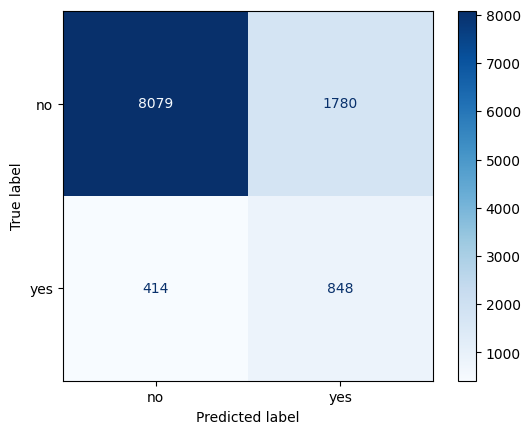

In [ ]:
ConfusionMatrixDisplay.from_estimator(
    clf,
    X_test,
    y_test,
    display_labels=["no", "yes"],
    cmap="Blues"
)

In [ ]:
from lets_plot import *

tree_importance = (
    pl.DataFrame({
        "feature": X_train.columns,
        "importance": clf.feature_importances_
    })
    .sort("importance", descending=True)
)

tree_importance.head(10)

ggplot(
    tree_importance.head(10).sort("importance"),
    aes(x="importance", y="feature")
) + \
    geom_bar(stat="identity") + \
    labs(
        title="Decision Tree Feature Importance",
        x="Importance",
        y="Feature"
    )

In [ ]:
###  Testing (mini-holdout)

# Test document
# test = pl.read_csv(
#     "https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bank_holdout_test_mini.csv",
#     schema_overrides={'nr.employed': pl.Float64},
# )

test = pl.read_csv(
    "https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bank_holdout_test.csv",
    schema_overrides={'nr.employed': pl.Float64},
)

# Transform the test data using the exact same prep as the training data
test = prep(test)

# Add any dummy columns the holdout is missing (e.g. default_yes), filled with 0
test = test.with_columns(
    [
        pl.lit(0).alias(col)
        for col in X.columns
        if col not in test.columns
    ]
)

# only use columns that we had in the training data, in the same order
test = test.select(X.columns)

predictions = clf.predict(test).astype(int)

# Convert the predictions to a dataframe and label the column 'predictions'
predictions = pl.DataFrame(predictions, schema=['predictions'])

predictions.write_csv("bank-telemarketing-predictions.csv")

predictions["predictions"].value_counts()

predictions,count
i64,u32
0,3165
1,954


In [ ]:
plot_df = campaign.select(['campaign', 'previous']).with_columns(
    pl.Series('y', y)
)

plot_df.head()

from lets_plot import *
LetsPlot.setup_html()

plot_pl = (
    plot_df
    .filter(pl.col('campaign') <= 15)
    .with_columns(pl.col('y').replace_strict({False: 'no', True: 'yes'}))
)

(
    ggplot(plot_pl, aes(x='campaign', fill='y'))
    + geom_histogram(aes(y='..density..'), binwidth=1)
    + facet_wrap('y', nrow = 1)
    + labs(title='campaign by signup', y='share within group')
    + theme_classic()
    + ggsize(900, 400)
)



In [ ]:
(
    campaign
    .with_columns(pl.Series('y', y))
    .group_by('marital', "day_of_week")
    .agg(
        pl.col('y').mean().alias('yes_rate'),
        pl.len().alias('n'),
    )
    .sort("yes_rate", descending = True)
)

day_order = ['mon', 'tue', 'wed', 'thu', 'fri']

(
    X_test
    .with_columns(
        pl.Series('y', y_test),
        pl.Series('pred', pred),
        pl.col('nr.employed').qcut(3, labels=['low', 'mid', 'high'], allow_duplicates=True).alias('employ'),
    )
    .group_by('employ')
    .agg(
        pl.len().alias('n'),
        pl.col('y').mean().alias('yes_rate'),
        (pl.col('pred') == pl.col('y')).mean().alias('accuracy'),
        ((pl.col('pred') & pl.col('y')).sum() / pl.col('y').sum()).alias('recall'),
    )
    .sort('employ')
)

employ,n,yes_rate,accuracy,recall
cat,u32,f64,f64,f64
"""low""",5798,0.167127,0.671093,0.862745
"""mid""",5323,0.055044,0.946083,0.040956
